BB84 experiment started.
Bits per trial: 1500
Number of trials: 3

TRIAL 1

Running Processor A, trial 1...
QBER: 0.000%
Candidate key length: 590
Keys match: False
Average circuit depth: 2.77
Average gate count: 2.77
Total experiment time: 0.734 seconds

Running Processor B, trial 1...
QBER: 1.361%
Candidate key length: 590
Keys match: False
Average circuit depth: 2.77
Average gate count: 2.77
Total experiment time: 0.742 seconds

TRIAL 2

Running Processor A, trial 2...
QBER: 0.649%
Candidate key length: 614
Keys match: False
Average circuit depth: 2.72
Average gate count: 2.72
Total experiment time: 0.634 seconds

Running Processor B, trial 2...
QBER: 1.299%
Candidate key length: 614
Keys match: False
Average circuit depth: 2.72
Average gate count: 2.72
Total experiment time: 0.938 seconds

TRIAL 3

Running Processor A, trial 3...
QBER: 0.685%
Candidate key length: 584
Keys match: False
Average circuit depth: 2.77
Average gate count: 2.77
Total experiment time: 0.693 seconds

Runnin

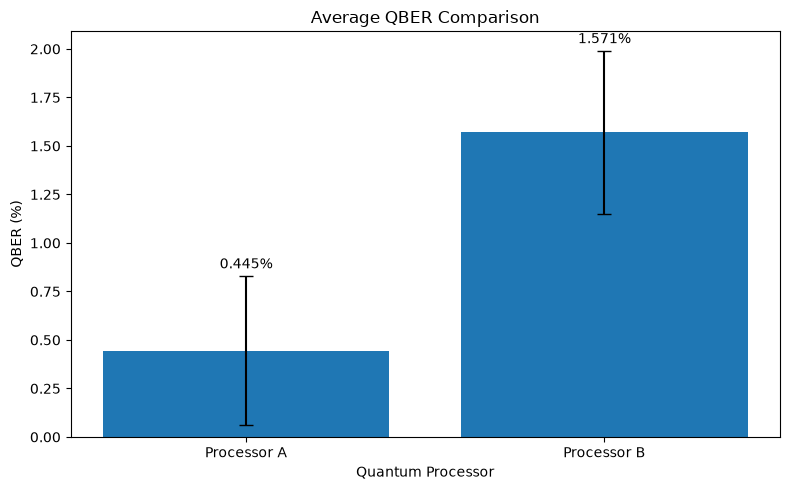


PROCESSOR TOPOLOGY COMPARISON

Processor A topology benchmark
Physical qubits: 5
Transpiled circuit depth: 11
Transpiled gate count: 15
CX gate count: 7
SWAP gate count: 0
GHZ correlated-output rate: 93.07%

Processor B topology benchmark
Physical qubits: 7
Transpiled circuit depth: 11
Transpiled gate count: 15
CX gate count: 7
SWAP gate count: 0
GHZ correlated-output rate: 85.64%


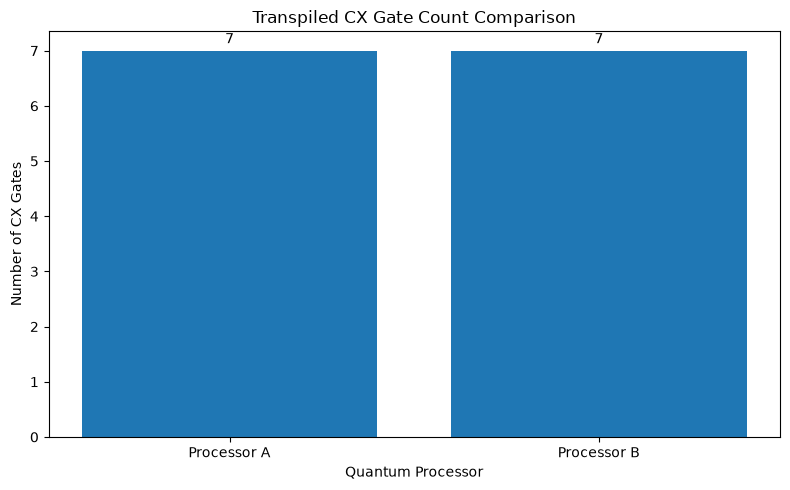


IDEAL BB84 MESSAGE DEMONSTRATION
Ideal channel QBER: 0.000%
Candidate keys match: True

Original message: Hello Bob! BB84 demonstration.
Encrypted bits (first 64): [1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1]
Received message: Hello Bob! BB84 demonstration.
Message received correctly: True

EXPERIMENT COMPLETED

Generated files:
results/tables/metrics.csv
results/tables/summary.csv
results/tables/architecture_metrics.csv
results/figures/qber_comparison.png
results/figures/architecture_comparison.png

Note: Processor A and B are synthetic simulated profiles.
The GHZ benchmark compares transpiled resource use and noisy
measurement correlations, not physical hardware performance.


In [ ]:

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

from src.qkd import (
    generate_bb84_job,
    calculate_qber,
    encrypt_message,
    decrypt_message
)

from processors.hardware import processor_a, processor_b

import matplotlib.pyplot as plt
import pandas as pd
import random
import statistics
import time
import os


# Experiment settings
N_BITS = 1500
N_TRIALS = 3
TEST_FRACTION = 0.20
RANDOM_SEED = 42

os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/tables", exist_ok=True)

print("BB84 experiment started.")
print("Bits per trial:", N_BITS)
print("Number of trials:", N_TRIALS)


# Run one BB84 experiment on a processor
def run_processor_trial(
    processor,
    circuits,
    alice_bits,
    alice_bases,
    bob_bases,
    trial_number,
    simulator_seed
):

    name = processor["name"]
    backend = processor["backend"]
    noise_model = processor["noise_model"]

    print(f"\nRunning {name}, trial {trial_number}...")

    start_time = time.time()

    transpiled_circuits = transpile(
        circuits,
        backend=backend,
        optimization_level=1
    )

    total_depth = sum(
        circuit.depth()
        for circuit in transpiled_circuits
    )

    total_gates = sum(
        circuit.size()
        for circuit in transpiled_circuits
    )

    simulator = AerSimulator(noise_model=noise_model)

    job = simulator.run(
        transpiled_circuits,
        shots=1,
        memory=True,
        seed_simulator=simulator_seed
    )

    result = job.result()

    # Get the measurement result from each circuit.
    bob_results = [
        result.get_memory(i)[0]
        for i in range(len(transpiled_circuits))
    ]

    # Estimate QBER and generate candidate keys.
    qber, key_alice, key_bob = calculate_qber(
        alice_bits,
        alice_bases,
        bob_bases,
        bob_results,
        test_fraction=TEST_FRACTION,
        rng=random.Random(RANDOM_SEED + trial_number + 1000)
    )

    total_time = time.time() - start_time

    avg_depth = total_depth / len(transpiled_circuits)
    avg_gates = total_gates / len(transpiled_circuits)

    print(f"QBER: {qber * 100:.3f}%")
    print("Candidate key length:", len(key_alice))
    print("Keys match:", key_alice == key_bob)
    print(f"Average circuit depth: {avg_depth:.2f}")
    print(f"Average gate count: {avg_gates:.2f}")
    print(f"Total experiment time: {total_time:.3f} seconds")

    return {
        "processor": name,
        "trial": trial_number,
        "qber": qber,
        "key_alice": key_alice,
        "key_bob": key_bob,
        "key_length": len(key_alice),
        "keys_match": key_alice == key_bob,
        "avg_depth": avg_depth,
        "avg_gates": avg_gates,
        "total_time": total_time
    }


# Run the same BB84 input on both processors
trial_results = []

for trial in range(1, N_TRIALS + 1):

    print("\n" + "=" * 50)
    print(f"TRIAL {trial}")
    print("=" * 50)

    # Both processors receive the same Alice/Bob inputs.
    circuits, alice_bits, alice_bases, bob_bases = generate_bb84_job(
        n_bits=N_BITS,
        rng=random.Random(RANDOM_SEED + trial)
    )

    result_a = run_processor_trial(
        processor_a,
        circuits,
        alice_bits,
        alice_bases,
        bob_bases,
        trial,
        RANDOM_SEED + trial * 100 + 1
    )

    result_b = run_processor_trial(
        processor_b,
        circuits,
        alice_bits,
        alice_bases,
        bob_bases,
        trial,
        RANDOM_SEED + trial * 100 + 2
    )

    trial_results.extend([result_a, result_b])


# Summarise the BB84 results
print("\n" + "=" * 50)
print("BB84 RESULTS SUMMARY")
print("=" * 50)

summary_rows = []

for name in ["Processor A", "Processor B"]:

    results = [
        item for item in trial_results
        if item["processor"] == name
    ]

    qber_values = [
        item["qber"] * 100
        for item in results
    ]

    mean_qber = statistics.mean(qber_values)

    std_qber = (
        statistics.stdev(qber_values)
        if len(qber_values) > 1 else 0
    )

    mean_key_length = statistics.mean(
        item["key_length"] for item in results
    )

    matching_trials = sum(
        item["keys_match"] for item in results
    )

    print(f"\n{name}")
    print(f"Mean QBER: {mean_qber:.3f}%")
    print(f"QBER standard deviation: {std_qber:.3f}%")
    print(f"Average candidate key length: {mean_key_length:.1f}")
    print(f"Trials with matching keys: {matching_trials}/{N_TRIALS}")

    summary_rows.append({
        "Processor": name,
        "Mean QBER (%)": mean_qber,
        "QBER Standard Deviation (%)": std_qber,
        "Average Candidate Key Length": mean_key_length,
        "Matching Key Trials": matching_trials
    })


# Save BB84 trial metrics
trial_table = pd.DataFrame([
    {
        "Processor": item["processor"],
        "Trial": item["trial"],
        "QBER (%)": item["qber"] * 100,
        "Candidate Key Length": item["key_length"],
        "Keys Match": item["keys_match"],
        "Average Circuit Depth": item["avg_depth"],
        "Average Gate Count": item["avg_gates"],
        "Total Time (seconds)": item["total_time"]
    }
    for item in trial_results
])

trial_table.to_csv(
    "results/tables/metrics.csv",
    index=False
)


# Save processor summary
summary_table = pd.DataFrame(summary_rows)

summary_table.to_csv(
    "results/tables/summary.csv",
    index=False
)


# Plot QBER comparison
plt.figure(figsize=(8, 5))

bars = plt.bar(
    summary_table["Processor"],
    summary_table["Mean QBER (%)"],
    yerr=summary_table["QBER Standard Deviation (%)"],
    capsize=5
)

plt.title("Average QBER Comparison")
plt.xlabel("Quantum Processor")
plt.ylabel("QBER (%)")

plt.bar_label(bars, fmt="%.3f%%", padding=3)

plt.tight_layout()

plt.savefig(
    "results/figures/qber_comparison.png",
    dpi=300
)

plt.show()


# Build a five-qubit GHZ circuit for topology comparison
def create_ghz_circuit():

    qc = QuantumCircuit(5, 5)

    qc.h(0)

    for target in range(1, 5):
        qc.cx(0, target)

    qc.measure(range(5), range(5))

    return qc


# Compare how the two topologies handle the same circuit
def run_topology_benchmark(processor):

    name = processor["name"]
    backend = processor["backend"]

    circuit = create_ghz_circuit()

    transpiled = transpile(
        circuit,
        backend=backend,
        optimization_level=1
    )

    operations = dict(transpiled.count_ops())

    cx_count = operations.get("cx", 0)
    swap_count = operations.get("swap", 0)

    simulator = AerSimulator(
        noise_model=processor["noise_model"]
    )

    result = simulator.run(
        transpiled,
        shots=1024,
        seed_simulator=RANDOM_SEED + processor["qubits"]
    ).result()

    counts = result.get_counts()

    # GHZ measurements ideally produce only 00000 or 11111.
    successful_shots = (
        counts.get("00000", 0) +
        counts.get("11111", 0)
    )

    success_rate = successful_shots / 1024

    print(f"\n{name} topology benchmark")
    print("Physical qubits:", processor["qubits"])
    print("Transpiled circuit depth:", transpiled.depth())
    print("Transpiled gate count:", transpiled.size())
    print("CX gate count:", cx_count)
    print("SWAP gate count:", swap_count)
    print(f"GHZ correlated-output rate: {success_rate * 100:.2f}%")

    return {
        "Processor": name,
        "Physical Qubits": processor["qubits"],
        "Circuit Depth": transpiled.depth(),
        "Gate Count": transpiled.size(),
        "CX Gate Count": cx_count,
        "SWAP Gate Count": swap_count,
        "GHZ Correlated Output (%)": success_rate * 100
    }


print("\n" + "=" * 50)
print("PROCESSOR TOPOLOGY COMPARISON")
print("=" * 50)

topology_results = [
    run_topology_benchmark(processor_a),
    run_topology_benchmark(processor_b)
]

topology_table = pd.DataFrame(topology_results)

topology_table.to_csv(
    "results/tables/architecture_metrics.csv",
    index=False
)


# Plot the topology benchmark
plt.figure(figsize=(8, 5))

bars = plt.bar(
    topology_table["Processor"],
    topology_table["CX Gate Count"]
)

plt.title("Transpiled CX Gate Count Comparison")
plt.xlabel("Quantum Processor")
plt.ylabel("Number of CX Gates")

plt.bar_label(bars, padding=3)

plt.tight_layout()

plt.savefig(
    "results/figures/architecture_comparison.png",
    dpi=300
)

plt.show()


# Demonstrate encryption using an ideal BB84 channel
print("\n" + "=" * 50)
print("IDEAL BB84 MESSAGE DEMONSTRATION")
print("=" * 50)

demo_circuits, demo_alice_bits, demo_alice_bases, demo_bob_bases = (
    generate_bb84_job(
        n_bits=N_BITS,
        rng=random.Random(RANDOM_SEED + 500)
    )
)

ideal_simulator = AerSimulator()

demo_circuits = transpile(
    demo_circuits,
    optimization_level=1
)

demo_result = ideal_simulator.run(
    demo_circuits,
    shots=1,
    memory=True,
    seed_simulator=RANDOM_SEED + 501
).result()

demo_bob_results = [
    demo_result.get_memory(i)[0]
    for i in range(len(demo_circuits))
]

demo_qber, demo_key_alice, demo_key_bob = calculate_qber(
    demo_alice_bits,
    demo_alice_bases,
    demo_bob_bases,
    demo_bob_results,
    test_fraction=TEST_FRACTION,
    rng=random.Random(RANDOM_SEED + 502)
)

print(f"Ideal channel QBER: {demo_qber * 100:.3f}%")
print("Candidate keys match:", demo_key_alice == demo_key_bob)


# Interactive BB84 message transmission

print("\n" + "=" * 50)
print("QUANTUM SECURE COMMUNICATION CHANNEL")
print("=" * 50)

# Alice enters the message.
secret_message = input("\nAlice, enter your message for Bob: ")

if not secret_message:
    print("Please enter a message.")

else:
    # Calculate how many bits are needed for the message.
    message_length = len(secret_message.encode("utf-8")) * 8

    # Generate extra qubits because some bits are discarded
    # during basis reconciliation and QBER testing.
    required_qubits = max(100, message_length * 4)

    print("\nGenerating BB84 quantum circuits...")
    print("Message size:", message_length, "bits")
    print("Qubits generated:", required_qubits)

    circuits, alice_bits, alice_bases, bob_bases = generate_bb84_job(
        n_bits=required_qubits,
        rng=random.Random()
    )

    # Simulate the ideal quantum channel.
    simulator = AerSimulator()

    compiled_circuits = transpile(
        circuits,
        optimization_level=1
    )

    result = simulator.run(
        compiled_circuits,
        shots=1,
        memory=True
    ).result()

    bob_results = [
        result.get_memory(i)[0]
        for i in range(len(compiled_circuits))
    ]

    # Perform basis reconciliation and QBER estimation.
    qber, alice_key, bob_key = calculate_qber(
        alice_bits,
        alice_bases,
        bob_bases,
        bob_results,
        test_fraction=0.20,
        rng=random.Random()
    )

    print("\nBB84 protocol completed.")
    print(f"Estimated QBER: {qber * 100:.2f}%")
    print("Alice's candidate key length:", len(alice_key))
    print("Bob's candidate key length:", len(bob_key))

    # Check whether both parties have the same key.
    if alice_key != bob_key:
        print("\nTransmission aborted: keys do not match.")

    elif len(alice_key) < message_length:
        print("\nTransmission aborted: insufficient key length.")

    else:
        # Alice encrypts the message.
        ciphertext, original_length = encrypt_message(
            secret_message,
            alice_key
        )

        print("\nAlice encrypted the message.")
        print("Ciphertext (first 64 bits):", ciphertext[:64])

        # Bob decrypts using his copy of the key.
        received_message = decrypt_message(
            ciphertext,
            bob_key,
            original_length
        )

        print("\nBob received the message:")
        print(received_message)

        print(
            "\nSuccessful transmission:",
            received_message == secret_message
        )


if demo_key_alice == demo_key_bob:

    ciphertext, message_length = encrypt_message(
        secret_message,
        demo_key_alice
    )

    received_message = decrypt_message(
        ciphertext,
        demo_key_bob,
        message_length
    )

    print("\nOriginal message:", secret_message)
    print("Encrypted bits (first 64):", ciphertext[:64])
    print("Received message:", received_message)
    print("Message received correctly:", received_message == secret_message)

else:
    print("Message transmission skipped because the keys do not match.")


# Final output
print("\n" + "=" * 50)
print("EXPERIMENT COMPLETED")
print("=" * 50)

print("\nGenerated files:")
print("results/tables/metrics.csv")
print("results/tables/summary.csv")
print("results/tables/architecture_metrics.csv")
print("results/figures/qber_comparison.png")
print("results/figures/architecture_comparison.png")

print("\nNote: Processor A and B are synthetic simulated profiles.")
print("The GHZ benchmark compares transpiled resource use and noisy")
print("measurement correlations, not physical hardware performance.")
